In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import graphviz

In [2]:
def f(x):
    return 3*x**2-4*x+5

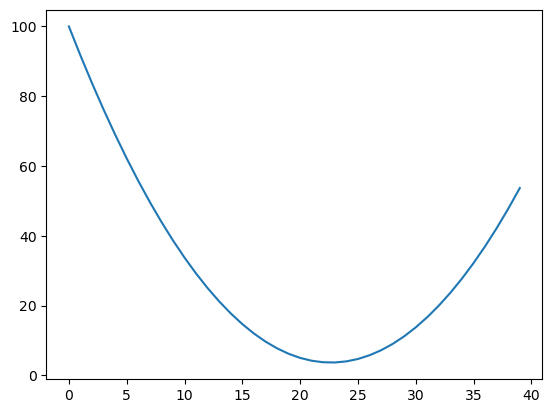

In [3]:
xs =np.arange(-5,5,0.25)
ys = f(xs)
plt.plot(ys)

In [4]:
h=0.001
x = 0.1
(f(x+h)-f(x))/h

-3.3969999999996503

In [5]:
class Value:
    def __init__(self,data,_children=(),_op='',label=''):
        self.data = data
        self.grad=0.0
        self._backward=lambda:None
        self._prev = set(_children)
        self._op =_op
        self.label = label
    def __repr__(self):
        return f'Value(data={self.data})'
    def __add__(self,other):
        other = other if isinstance(other,Value) else Value(other)
        out =  Value(self.data + other.data,(self,other),'+')
        def _backward():
            self.grad += 1.0*out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        return out
    def __mul__(self,other):
        other = other if isinstance(other,Value) else Value(other)
        out =  Value(self.data * other.data,(self,other),'*')
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward =_backward
        return out
    def __pow__(self,other):
        assert isinstance(other,(int,float)),'only supporting int/float powers for now'
        out = Value(self.data**other,(self,),f'**{other}')
        def _backward():
            self.grad += other *( self.data ** (other -1))*out.grad
        out._backward = _backward
        return out
    def __rmul__(self,other):
        return self*other
    def __truediv__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        return self * other**-1
    def __neg__(self):
        return self * -1
    def __sub__(self,other):
        return self +(-other)
    def tanh(self):
        x = self.data
        t = (np.exp(2*x)-1)/(np.exp(2*x)+1)
        out = Value(t,(self, ),'tanh')
        def _backward():
            self.grad += (1-t**2)*out.grad
        out._backward =_backward
        return out
    def exp(self):
        x = self.data
        out = Value(np.exp(x),(self, ),'exp')

        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward
        return out
    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

            
    



a = Value(2.0,label='a')
b = Value(-3.0,label='b')
c = Value(10.0,label='c')
e = a*b;e.label='e'
d = e + c; d.label='d'
f = Value(-2.0,label='f')
L = d * f ; L.label='L'
L

Value(data=-8.0)

In [6]:
from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges


def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})  # LR = left to right
    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # Node with label showing data and grad
        dot.node(name=uid, 
                 label='{%s|data %.4f|grad %.4f}' % (n.label, n.data, n.grad), 
                 shape='record')
        
        # If operation exists, add op node
        if n._op:
            dot.node(name=uid + n._op, label=n._op)
            dot.edge(uid + n._op, uid)
            
    # Add edges between nodes
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    
    return dot


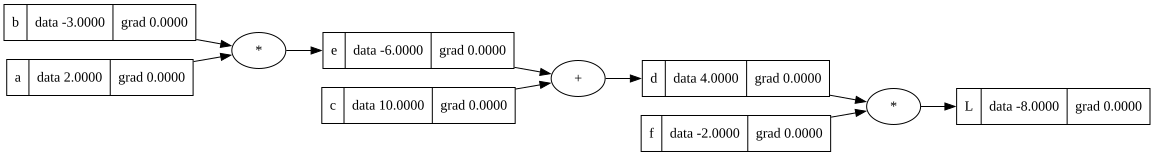

In [7]:
draw_dot(L)

In [8]:
L.grad = 1.0
f.grad=4.0
d.grad=-2.0
c.grad= -2.0
e.grad=-2.0
a.grad=-3.00*-2.00
b.grad=(-2.0 * 2.0)


In [9]:
a.data += 0.01 * a.grad
b.data += 0.01 * b.grad
c.data += 0.01 * c.grad
f.data += 0.01 * f.grad
e = a * b
d = e + c
L = d * f 
L


Value(data=-7.286496)

In [10]:
## L = d * f
##dl/dd = f
##(f(x+h)-f(x))/h
#((d+h)*f-d*f)/h
#((df+hf-df))/h
#f
##dd/dc  = 1.0
#dd/de = 1.0
# d = c+ e
# ((c+h+e) -(c+e))/h
# (c+h+e-c-e)/h


In [11]:
def lol():
  h=0.0001
  a = Value(2.0,label='a')
  b = Value(-3.0,label='b')
  c = Value(10.0,label='c')
  e = a*b;e.label='e'
  d = e + c; d.label='d' 
  
  f=Value(-2.0,label='f')
  L=d*f; L.label='L'
  L1=L.data
  L1
    
  a = Value(2.0,label='a')
  b = Value(-3.0,label='b')
  c = Value(10.0,label='c')
  e = a*b;e.label='e'
  d = e + c; d.label='d'
  f=Value(-2.0,label='f')
  L=d*f; L.label='L'
  L2=L.data

  print((L2-L1)/h)



lol()

0.0


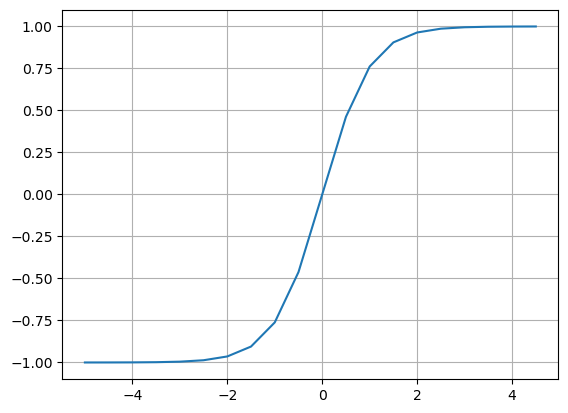

In [12]:
plt.plot(np.arange(-5,5,0.5),np.tanh(np.arange(-5,5,0.5)))
plt.grid()

In [13]:
##input x1,x2
x1 = Value(2.0,label='x1')
x2 = Value(0.0,label='x2')
#weight w1,w2
w1 = Value(-3.0,label='w1')
w2 = Value(1.0,label='w2')
#bais
b = Value(6.8813735870195432,label='b')
#x1w1 *x2w2+ b
x1w1 = x1*w1; x1w1.label='x1w1'
x2w2 = x2*w2; x2w2.label='x2w2'
x1w1x2w2 = x1w1 + x2w2;x1w1x2w2.label='x1w2 * x2w2'

n = x1w1x2w2 +b; n.label='n'
o = n.tanh();o.label='o'


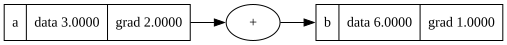

In [14]:
a = Value(3.0, label='a')
b = a+a ; b.label='b'
b.backward()
draw_dot(b)

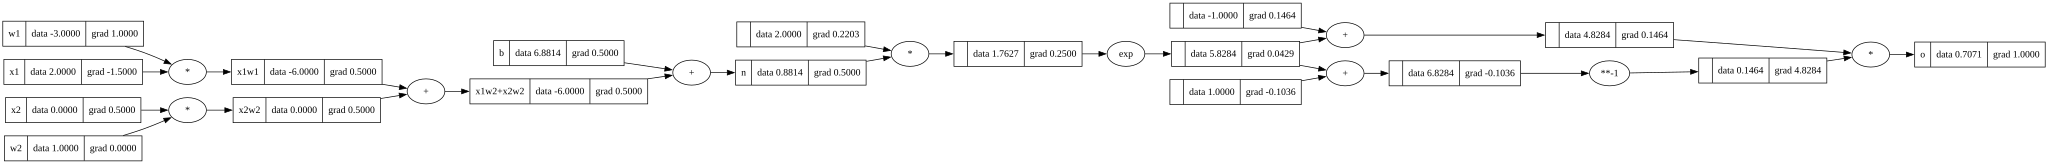

In [15]:
##input x1,x2
x1 = Value(2.0,label='x1')
x2 = Value(0.0,label='x2')
#weight w1,w2
w1 = Value(-3.0,label='w1')
w2 = Value(1.0,label='w2')
#bais
b = Value(6.8813735870195432,label='b')
#x1w1 *x2w2+ b
x1w1 = x1*w1; x1w1.label='x1w1'
x2w2 = x2*w2; x2w2.label='x2w2'
x1w1x2w2 = x1w1 + x2w2;x1w1x2w2.label='x1w2+x2w2'
n = x1w1x2w2 + b; n.label='n'
e = (2*n).exp()
o = (e-1)/(e+1)
o.label = 'o'
o.backward()
draw_dot(o)



In [16]:
#pytorch

In [17]:
import torch

In [18]:
import torch

# inputs
x1 = torch.tensor([2.0], dtype=torch.double, requires_grad=True)
x2 = torch.tensor([0.0], dtype=torch.double, requires_grad=True)

# weights
w1 = torch.tensor([0.0], dtype=torch.double, requires_grad=True)
w2 = torch.tensor([0.0], dtype=torch.double, requires_grad=True)

# bias
b = torch.tensor([6.8813735870195432], dtype=torch.double, requires_grad=True)

# forward pass (FIXED: use w1 and w2 correctly)
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

# print output (FIXED)
print(o.item())

# backward
o.backward()

print('----')

# grads (FIXED: these are scalars, so .item() works)
print('x1', x1.grad.item())
print('x2', x2.grad.item())
print('w1', w1.grad.item())
print('w2', w2.grad.item())
print('b', b.grad.item())

0.9999978916418634
----
x1 0.0
x2 0.0
w1 8.433423656084571e-06
w2 0.0
b 4.2167118280422855e-06


In [19]:
import random

class Neuron:
    def __init__(self, nin):
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))
    def __call__(self, x):
        # convert inputs to Value
        act = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        return act.tanh()
    def parameters(self):
        return self.w + [self.b]


class Layer:
    def __init__(self,nin,nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self,x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs
    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]
class MLP:
    def __init__(self,nin,nouts):
       sz = [nin] + nouts
       self.layer = [Layer(sz[i],sz[i+1]) for i in range(len(nouts))]

    def __call__(self,x):
        for layer in self.layer:
            x = layer(x)
        return x
    def parameters(self):
        return [p for layer in self.layer for p in layer.parameters()]




In [20]:
x = [ 2.0,3.0,-1.0]
n = MLP(3,[4,4,1])
n(x)

Value(data=0.08152967064345465)

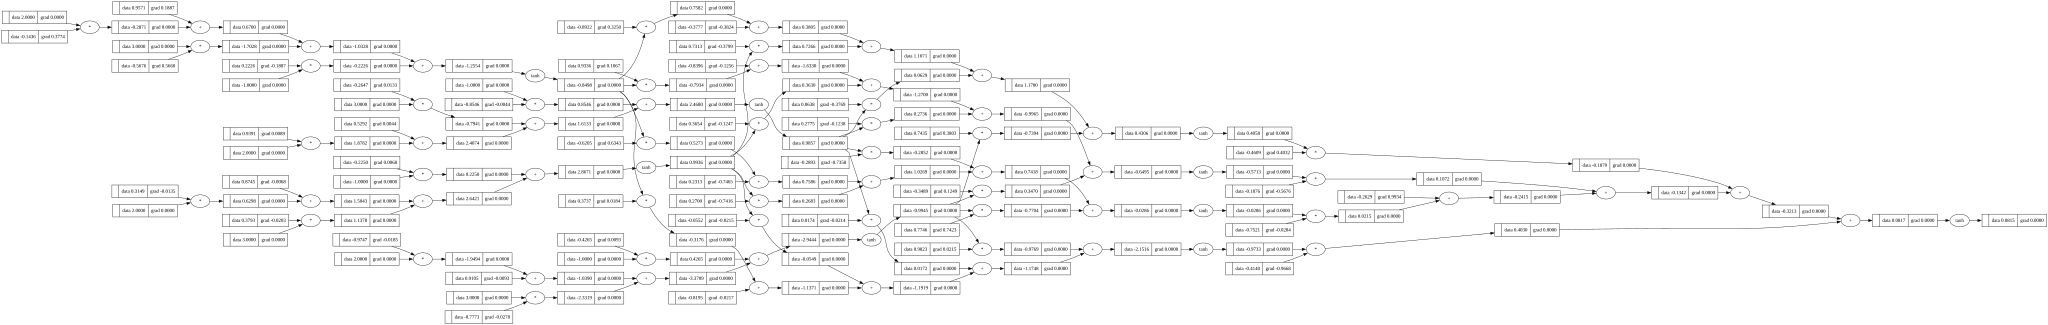

In [21]:
n(x).backward()
draw_dot(n(x))

In [22]:
xs = [
    [2.0,3.0,-1.0],
    [3.0,-1.0,0.5],
    [1.0,1.0,1.0],
    [1.0,1.0,-1.0]
]

ys = [1.0,-1.0,-1.0]# desired target
ypred =[n(x) for x in xs]
ypred

[Value(data=0.08152967064345465),
 Value(data=0.7289542742664489),
 Value(data=0.6276769858391099),
 Value(data=0.15215523520986557)]

In [23]:
ys = [Value(y) for y in ys]
loss = sum(((yout - ygt)**2 for ygt, yout in zip(ys, ypred)),Value(0.0))
loss


Value(data=6.482202998642834)

In [24]:
loss.backward()

In [25]:
n.layer[0].neurons[0].w[0].grad


np.float64(0.640976994760956)

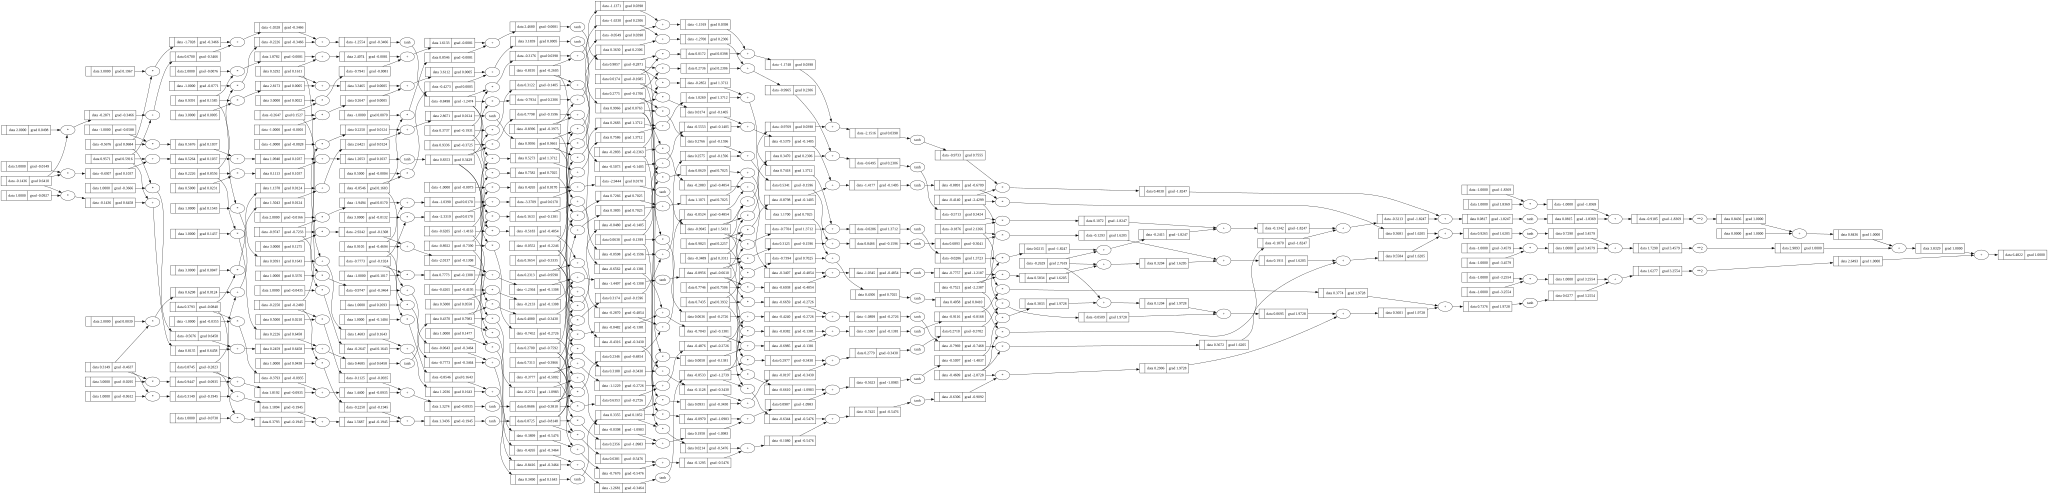

In [26]:
draw_dot(loss)

In [27]:
n.layer[0].neurons[0].w[0].data

-0.14356322240606545

In [28]:
for k in range(20):
    # forward pass
    ypred = [n(x) for x in xs]
    loss = sum(((yout - ygt)**2 for ygt, yout in zip(ys, ypred)), Value(0.0))

    # zero gradients
    for p in n.parameters():
        p.grad = 0.0

    # backward pass
    loss.backward()

    # update
    for p in n.parameters():
        p.data += -0.01 * p.grad

    print(k, loss.data)


0 6.482202998642834
1 6.095658962655694
2 5.650833953249419
3 5.1420353358899815
4 4.582724550653805
5 4.010458099271554
6 3.476553683130714
7 3.020972016835374
8 2.654984488526903
9 2.3667278355871995
10 2.136692746202077
11 1.9476382675203627
12 1.7872643248864102
13 1.6475702895721354
14 1.5235328637725847
15 1.4119981494675735
16 1.3109264489424022
17 1.2189221723417165
18 1.1349574318258382
19 1.0582168315442928


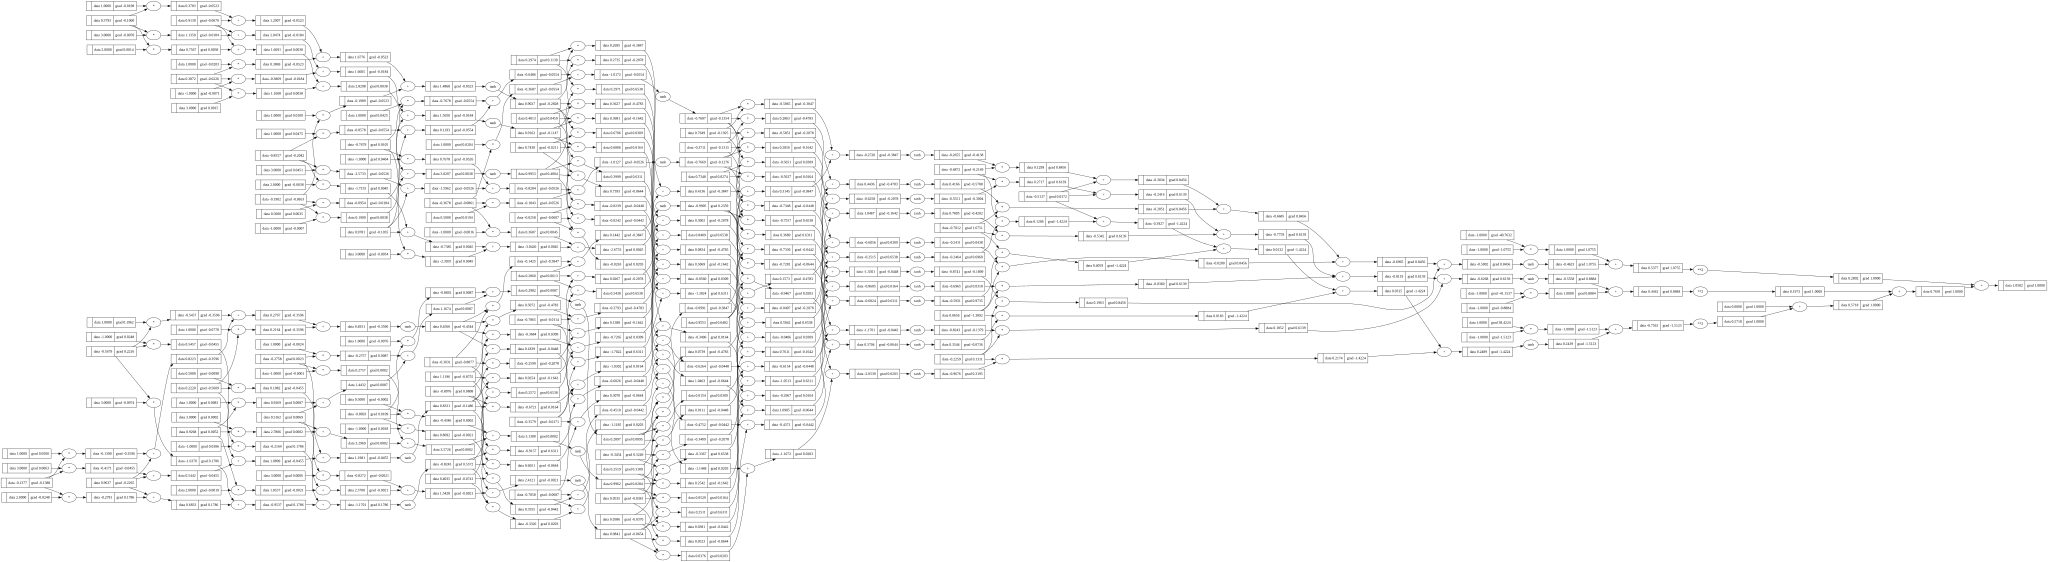

In [29]:
draw_dot(loss)